**07 · Comparación contextual con modelos DNN en ModelNet10/40**

**Advertencia importante:** la comparación con DNN suele ser **contextual y no estrictamente justa**. La mayoría de los DNN reportan **clasificación supervisada top-1**, mientras que tu tesis reporta sobre todo **recuperación (mAP, 1-NN)** y, en algunos casos, agrupamiento. Este cuaderno separa explícitamente ambas cosas para evitar afirmaciones engañosas.

In [2]:
from pathlib import Path
import sys, subprocess, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'benchmarks'/'common.py').exists() and (p/'pyproject.toml').exists()), None)
if ROOT is None:
    raise RuntimeError("Abre Jupyter desde la raíz de point-field o una subcarpeta del repositorio.")
sys.path.insert(0, str(ROOT/'benchmarks'))
OUT = ROOT/'runs'/'tesis_figuras'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'figure.dpi': 120, 'savefig.dpi': 300, 'pdf.fonttype': 42})
COLORS = ['#21618c','#c65036','#63933e','#8b65a5','#c49a38','#458e91','#d16c9f','#555555']
def save(fig, name):
    for ext in ('pdf','png'):
        fig.savefig(OUT/f'{name}.{ext}', bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)
def points(ax, X, y=None, s=6):
    X=np.asarray(X)
    if y is None:
        if X.shape[1]==2: ax.scatter(X[:,0],X[:,1],s=s,c=COLORS[0],linewidths=0)
        else: ax.scatter(X[:,0],X[:,1],X[:,2],s=s,c=COLORS[0],linewidths=0)
    else:
        labs=np.unique(y)
        for j,c in enumerate(labs):
            col='#b9b9b9' if c==-1 else COLORS[j%len(COLORS)]
            m=(y==c)
            if X.shape[1]==2: ax.scatter(X[m,0],X[m,1],s=s,c=col,linewidths=0)
            else: ax.scatter(X[m,0],X[m,1],X[m,2],s=s,c=col,linewidths=0)
    ax.set_xticks([]); ax.set_yticks([])
    if X.shape[1]==2:
        ax.set_aspect('equal', adjustable='box')
    else:
        ax.set_zticks([]); ax.set_box_aspect((1,1,1)); ax.view_init(elev=23, azim=35)
def run_script(name, *args):
    subprocess.run([sys.executable, str(ROOT/'benchmarks'/name), *map(str,args)], cwd=ROOT, check=True)
print('Repositorio:', ROOT, 'Salidas:', OUT)
try:
    commit=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip()
except Exception:
    commit='No disponible'
print('Commit:', commit)


Repositorio: /home/icantu24/Documents/PEF-CD/point-field Salidas: /home/icantu24/Documents/PEF-CD/point-field/runs/tesis_figuras
Commit: 88445aa61ca2a66afcc53a931cf0927232ef232f


**1. Cargar o crear plantilla de baselines DNN.** Llena la plantilla con valores verificados de artículos o repositorios oficiales. Si no tienes aún los números, el cuaderno deja lista la estructura y aún así puede graficar tus resultados.

In [3]:
BASE = ROOT/'notebooks_tesis'/'dnn_baselines_modelnet_template.csv'
if not BASE.exists():
    tmpl = pd.DataFrame([
        ['ModelNet10','PointNet','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
        ['ModelNet10','PointNet++','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
        ['ModelNet10','DGCNN','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
        ['ModelNet10','Point Transformer','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
        ['ModelNet40','PointNet','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
        ['ModelNet40','PointNet++','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
        ['ModelNet40','DGCNN','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
        ['ModelNet40','Point Transformer','supervisado','top1_acc',np.nan,'TODO: verificar paper y protocolo','',''],
    ], columns=['dataset','method','family','metric','value','notes','source_short','source_url'])
    BASE.parent.mkdir(parents=True, exist_ok=True)
    tmpl.to_csv(BASE, index=False)
base = pd.read_csv(BASE)
display(base)
print('Plantilla:', BASE)


,dataset,method,family,metric,value,notes,source_short,source_url
0,ModelNet10,PointNet,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN
1,ModelNet10,PointNet++,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN
2,ModelNet10,DGCNN,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN
3,ModelNet10,Point Transformer,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN
4,ModelNet40,PointNet,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN
5,ModelNet40,PointNet++,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN
6,ModelNet40,DGCNN,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN
7,ModelNet40,Point Transformer,supervisado,top1_acc,NaN,TODO: verificar paper y protocolo,NaN,NaN


Plantilla: /home/icantu24/Documents/PEF-CD/point-field/notebooks_tesis/dnn_baselines_modelnet_template.csv


**2. Cargar resultados de la tesis.** El notebook intenta extraer lo mejor de ModelNet10 y ModelNet40 en términos de mAP y 1-NN. Ajusta los alias de método si tus CSV usan otra nomenclatura.

In [4]:
def load_modelnet(name):
    path = ROOT/'benchmarks/results'/f'{name}_test.csv'
    if not path.exists():
        print('No existe', path)
        return None
    df=pd.read_csv(path)
    print(name, path)
    display(df.head())
    return df
mn10=load_modelnet('modelnet10')
mn40=load_modelnet('modelnet40')

ALIASES = {
    'CD + m':['CD + m','CD+m','CD_U+m','CD metric'],
    'Momentos + m':['Momentos + m','M_U+m','moment metric','momentos+m'],
    'CD':['CD','CD_U'],
    'Momentos':['Momentos','M_U'],
    'D2':['D2'],
}

def best_rows(df, dataset_name):
    if df is None: return pd.DataFrame()
    mcol = next((c for c in df.columns if 'method' in c.lower()), None)
    cond = next((c for c in df.columns if 'condition' in c.lower()), None)
    nn = next((c for c in df.columns if c.lower() in ('nn','top1','1nn')), None)
    mp = next((c for c in df.columns if c.lower()=='map'), None)
    rows=[]
    for label,pats in ALIASES.items():
        sub=df[df[mcol].astype(str).str.contains('|'.join(pats),case=False,regex=True)] if mcol else pd.DataFrame()
        if len(sub)==0: continue
        for condition in ['clean','noise','density','occlusion','outliers']:
            ss=sub[sub[cond].astype(str).str.contains(condition,case=False,regex=False)] if cond else sub
            if len(ss)==0: continue
            row={'dataset':dataset_name,'method':label,'condition':condition}
            if mp: row['mAP']=ss[mp].mean()
            if nn: row['1NN']=ss[nn].mean()
            rows.append(row)
    return pd.DataFrame(rows)

mine = pd.concat([best_rows(mn10,'ModelNet10'), best_rows(mn40,'ModelNet40')], ignore_index=True)
display(mine)
mine.to_csv(OUT/'07_modelnet_mis_resultados_resumen.csv', index=False)


modelnet10 /home/icantu24/Documents/PEF-CD/point-field/benchmarks/results/modelnet10_test.csv


,condition,method,mAP,nn,ci_low,ci_high
0,clean,CD_U,0.383049,0.695,NaN,NaN
1,clean,CD_W,0.365492,0.660,NaN,NaN
2,clean,M_U,0.398547,0.720,NaN,NaN
3,clean,D2,0.272121,0.440,NaN,NaN
4,clean,CD_U_metric,0.399552,0.725,NaN,NaN


modelnet40 /home/icantu24/Documents/PEF-CD/point-field/benchmarks/results/modelnet40_test.csv


,condition,method,mAP,nn,ci_low,ci_high
0,clean,CD_U,0.224984,0.4750,NaN,NaN
1,clean,CD_W,0.215241,0.4625,NaN,NaN
2,clean,M_U,0.220037,0.4800,NaN,NaN
3,clean,D2,0.151321,0.3225,NaN,NaN
4,clean,CD_U_metric,0.244542,0.5225,NaN,NaN


,dataset,method,condition,mAP,1NN
0,ModelNet10,CD,clean,0.259118,0.702500
1,ModelNet10,CD,noise,0.258552,0.695000
2,ModelNet10,CD,density,0.239899,0.635000
3,ModelNet10,CD,occlusion,0.233490,0.562500
4,ModelNet10,CD,outliers,0.148464,0.251250
5,ModelNet10,Momentos,clean,0.266033,0.740000
6,ModelNet10,Momentos,noise,0.265137,0.732500
7,ModelNet10,Momentos,density,0.246378,0.652500
8,ModelNet10,Momentos,occlusion,0.218383,0.492500
9,ModelNet10,Momentos,outliers,0.171183,0.285000


**3. Comparación visual.** El primer gráfico compara DNN supervisados entre sí. El segundo coloca tus mejores resultados 1-NN como referencia contextual. No mezclar top-1 supervisado con mAP en una sola tabla sin explicar la diferencia.

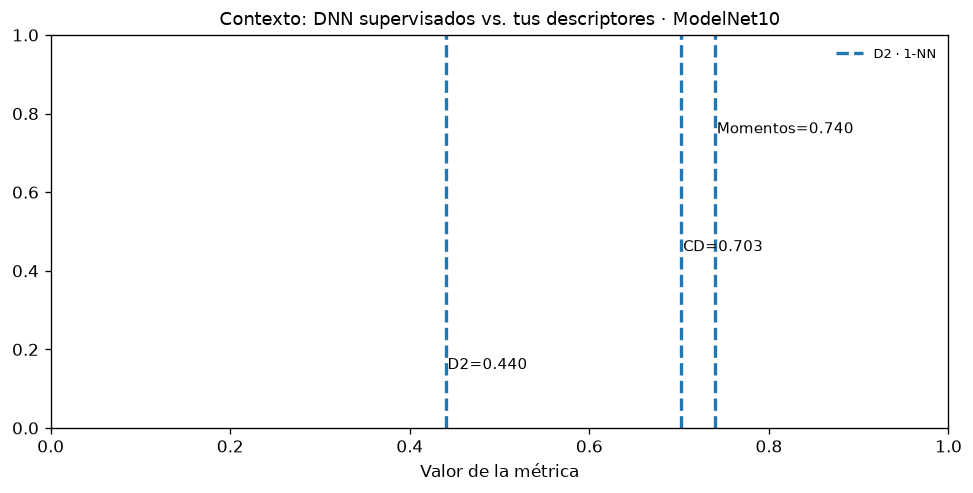

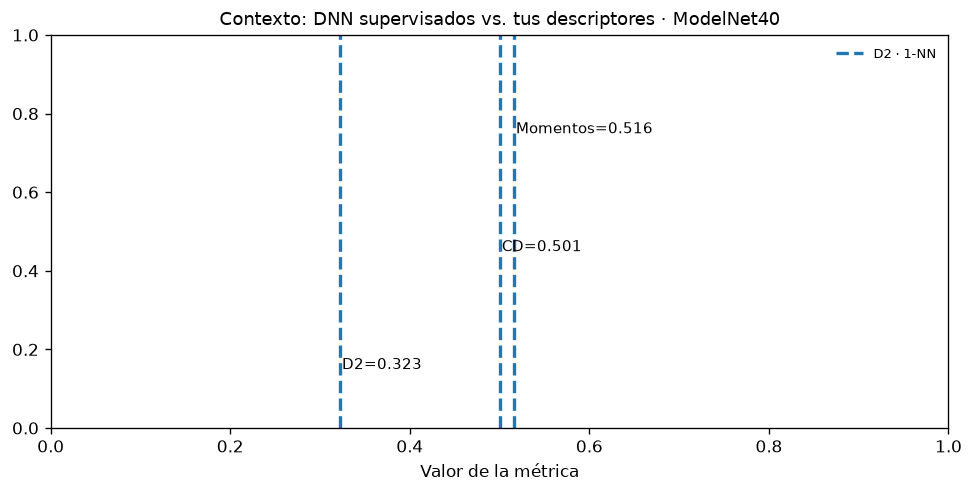

In [5]:
for dataset in ['ModelNet10','ModelNet40']:
    b = base[(base.dataset==dataset) & (base.metric=='top1_acc')].copy()
    if not b.empty and b['value'].notna().any():
        fig,ax=plt.subplots(figsize=(8,4), constrained_layout=True)
        b=b.sort_values('value')
        ax.barh(b['method'], b['value'])
        ax.set(title=f'Baselines DNN supervisados · {dataset}', xlabel='Top-1 accuracy')
        save(fig, f'07_dnn_baselines_{dataset.lower()}')

    my = mine[(mine.dataset==dataset) & (mine.condition=='clean')].copy()
    if not my.empty and '1NN' in my.columns:
        fig,ax=plt.subplots(figsize=(8,4), constrained_layout=True)
        if not b.empty and b['value'].notna().any():
            ax.barh(b['method'], b['value'], alpha=.55, label='DNN supervisados (top-1)')
        y0 = 0.15
        for i,(_,r) in enumerate(my.sort_values('1NN').iterrows()):
            ax.axvline(r['1NN'], linestyle='--', linewidth=2, label=f"{r['method']} · 1-NN" if i==0 else None)
            ax.text(r['1NN']+0.002, y0+i*0.3, f"{r['method']}={r['1NN']:.3f}", fontsize=9)
        ax.set(title=f'Contexto: DNN supervisados vs. tus descriptores · {dataset}', xlabel='Valor de la métrica')
        ax.legend(frameon=False, fontsize=8)
        save(fig, f'07_contexto_dnn_vs_mi_{dataset.lower()}')


**4. Tabla para el manuscrito.** Produce una tabla compacta con notas metodológicas para que la comparación quede bien justificada en la tesis.

In [6]:
rows=[]
for dataset in ['ModelNet10','ModelNet40']:
    b = base[(base.dataset==dataset) & (base.metric=='top1_acc')].copy()
    for _,r in b.iterrows():
        rows.append([dataset, r['method'], 'DNN supervisado', 'top-1', r['value'], r['notes']])
    my = mine[(mine.dataset==dataset) & (mine.condition=='clean')].copy()
    for _,r in my.iterrows():
        rows.append([dataset, r['method'], 'Descriptor no supervisado', 'mAP', r.get('mAP',np.nan), 'recuperación'])
        rows.append([dataset, r['method'], 'Descriptor no supervisado', '1-NN', r.get('1NN',np.nan), 'recuperación'])
comp = pd.DataFrame(rows, columns=['dataset','method','familia','métrica','valor','nota'])
display(comp)
comp.to_csv(OUT/'07_tabla_comparacion_dnn_modelnet.csv', index=False)
print('Recuerda citar explícitamente que la comparación es contextual y no apples-to-apples.')


,dataset,method,familia,métrica,valor,nota
0,ModelNet10,PointNet,DNN supervisado,top-1,NaN,TODO: verificar paper y protocolo
1,ModelNet10,PointNet++,DNN supervisado,top-1,NaN,TODO: verificar paper y protocolo
2,ModelNet10,DGCNN,DNN supervisado,top-1,NaN,TODO: verificar paper y protocolo
3,ModelNet10,Point Transformer,DNN supervisado,top-1,NaN,TODO: verificar paper y protocolo
4,ModelNet10,CD,Descriptor no supervisado,mAP,0.259118,recuperación
5,ModelNet10,CD,Descriptor no supervisado,1-NN,0.702500,recuperación
6,ModelNet10,Momentos,Descriptor no supervisado,mAP,0.266033,recuperación
7,ModelNet10,Momentos,Descriptor no supervisado,1-NN,0.740000,recuperación
8,ModelNet10,D2,Descriptor no supervisado,mAP,0.272121,recuperación
9,ModelNet10,D2,Descriptor no supervisado,1-NN,0.440000,recuperación


Recuerda citar explícitamente que la comparación es contextual y no apples-to-apples.
